[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/17_von_mises_fisher.py)

# Von Mises-Fisher Mixtures: Clustering Directions on the Sphere

Text and image embeddings, gene-expression profiles compared by correlation, wind or protein-backbone directions:
in many problems only the *direction* of a vector matters, and the data are L2-normalised before clustering by
cosine similarity. A Gaussian (or Student-t) mixture is the wrong model for such data: it is defined over all of
$\mathbb{R}^d$, spends parameters modelling vector *length* that normalisation has thrown away, and its
ellipsoids know nothing about the sphere. The **von Mises-Fisher (vMF)** distribution is the natural analogue
restricted to the unit hypersphere, and `VonMisesFisherMixture` (Banerjee, Dhillon, Ghosh & Sra, 2005) fits a
mixture of them with the same EM machinery and API as `GaussianMixture`.

**What you'll learn**

- what a von Mises-Fisher distribution looks like on the circle and the sphere, and how its concentration
  $\kappa$ and the dimension $d$ shape it;
- how EM estimates a vMF mixture: the resultant-vector M-step and the equation that defines $\kappa$, checked
  numerically against the library;
- how to visualise a fitted mixture: mean directions, concentration caps, and angle-to-mean histograms in any dimension;
- how to cluster high-dimensional unit-norm embeddings and compare with a Gaussian baseline -- and which comparisons
  are, and are not, meaningful.

**Prerequisites:** [01 -- Gaussian Mixture Models](01_gmm.ipynb) and [02 -- The EM Algorithm](02_em_algorithm.ipynb).
See also the [Other Mixture Families](../user-guide/other-mixture-families.md) user guide and the
[plotting guide](../user-guide/plotting.md#von-mises-fisher-mixtures).

## Setup

The next cell imports what the notebook needs and fixes the random seeds. It expects `tgmm` to be importable: `pip install tgmm`, or `pip install -e .` from a clone of the repository. Opened with `marimo edit --sandbox`, the dependencies listed in the header of this file are installed automatically.

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.special import i0e, ive

from tgmm import GaussianMixture, VonMisesFisherMixture, plot_vmf, plot_vmf_cosine, vmf_angle_density, vmf_cap_angle
from tgmm.metrics import ClusteringMetrics
from tgmm.plotting import CATEGORICAL_PALETTE, SEQUENTIAL_CMAP

plt.rcParams['figure.dpi'] = 100  # tgmm's theme uses 300 dpi; marimo embeds figures at 2x, so keep outputs small
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')

Using device: cpu


## What a von Mises-Fisher distribution looks like

A point on the unit sphere $S^{d-1}$ is a *direction*. The von Mises-Fisher (vMF) distribution with
mean direction $\mu$ ($\|\mu\|=1$) and concentration $\kappa\ge0$ has density

$$
f(x\mid\mu,\kappa)=C_d(\kappa)\,e^{\kappa\,\mu^{\top}x},\qquad
C_d(\kappa)=\frac{\kappa^{d/2-1}}{(2\pi)^{d/2}\,I_{d/2-1}(\kappa)},
$$

with $I_\nu$ the modified Bessel function of the first kind. The density depends on $x$ only through
the **cosine similarity** $\mu^{\top}x$, so it is largest at $x=\mu$ and constant on every circle of
points at the same angle from $\mu$. $\kappa=0$ is the uniform distribution on the sphere; large
$\kappa$ concentrates the mass around $\mu$ (roughly an isotropic Gaussian of variance $1/\kappa$
in the tangent plane).

### On the circle ($d=2$)

For $d=2$ the sphere is a circle and the vMF is the classical **von Mises** distribution of the angle
$\varphi$: $f(\varphi)=e^{\kappa\cos(\varphi-\varphi_0)}/(2\pi I_0(\kappa))$. The polar plot below
draws the density as the radius of a curve around the unit circle (dashed), for several $\kappa$.

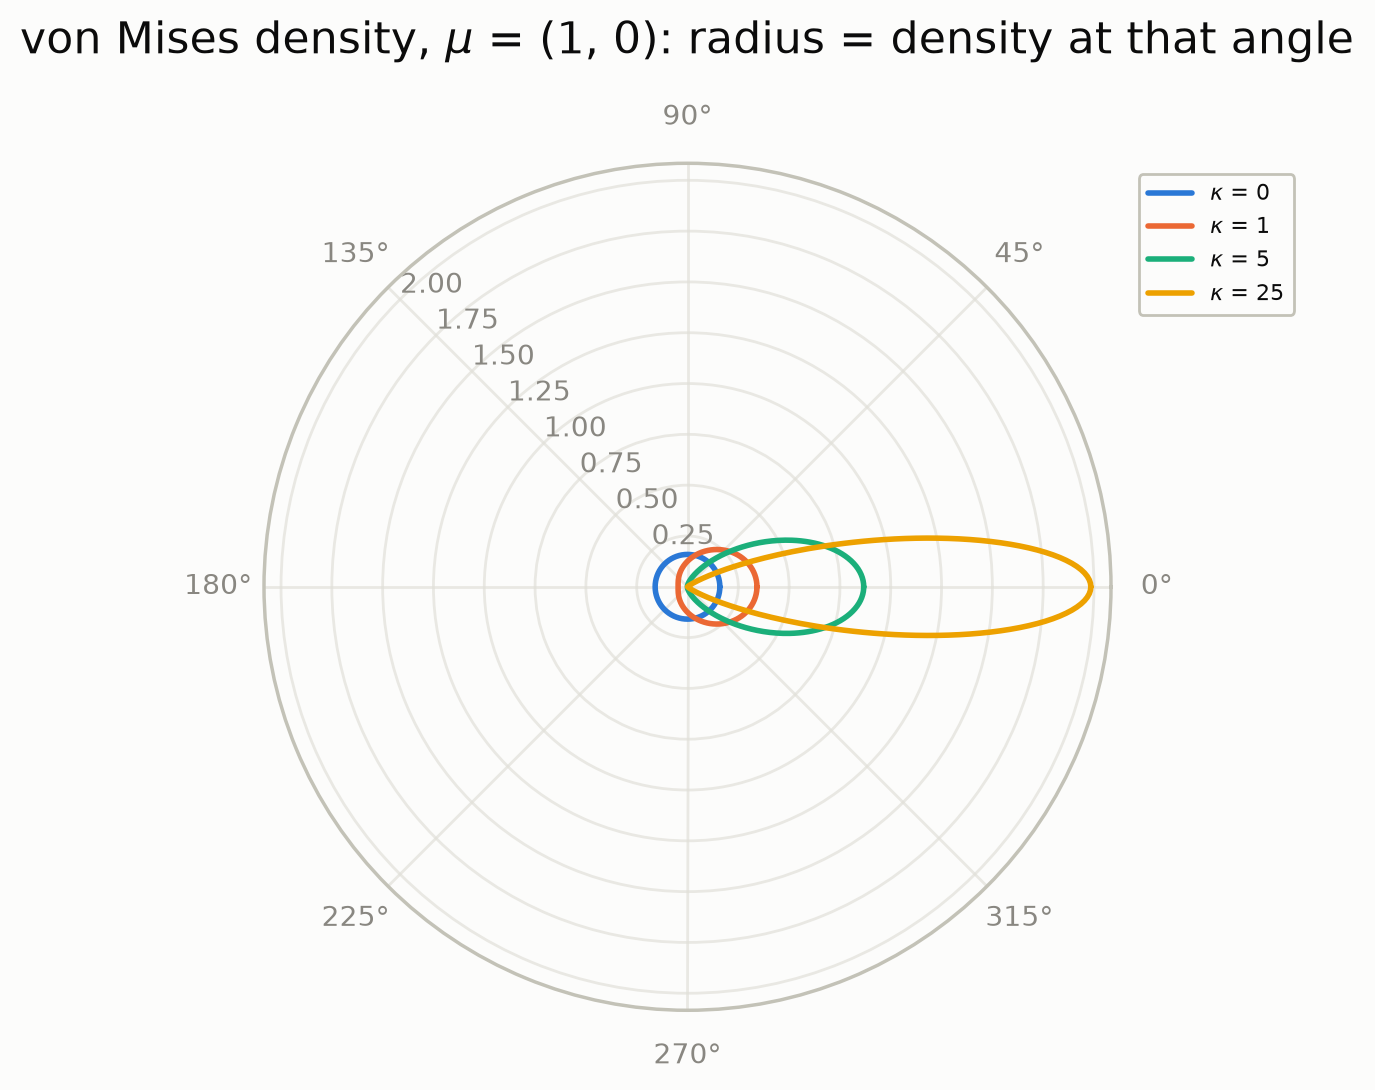

In [ ]:
phi = np.linspace(0, 2 * np.pi, 721)
kappas_demo = [0.0, 1.0, 5.0, 25.0]
_fig, _ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(5.5, 5.5))
for _kappa, _color in zip(kappas_demo, CATEGORICAL_PALETTE):
    density = np.exp(_kappa * (np.cos(phi) - 1.0)) / (2 * np.pi * i0e(_kappa))
    _ax.plot(phi, density, color=_color, label=f'$\\kappa$ = {_kappa:g}')  # e^{kappa cos(phi)} / (2 pi I_0(kappa)), with i0e(k) = e^{-k} I_0(k) for numerical stability
_ax.set_title('von Mises density, $\\mu$ = (1, 0): radius = density at that angle', pad=18)
_ax.set_rlabel_position(135)
_ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0))
plt.gcf()

### On the sphere ($d=3$)

For $d=3$, $C_3(\kappa)=\kappa/(4\pi\sinh\kappa)$. The surfaces below are coloured by density
(same colour scale in each panel, so the panels are directly comparable); $\mu$ points toward the
viewer's upper right. $\kappa=0.5$ is nearly uniform, $\kappa=30$ is a tight cap.

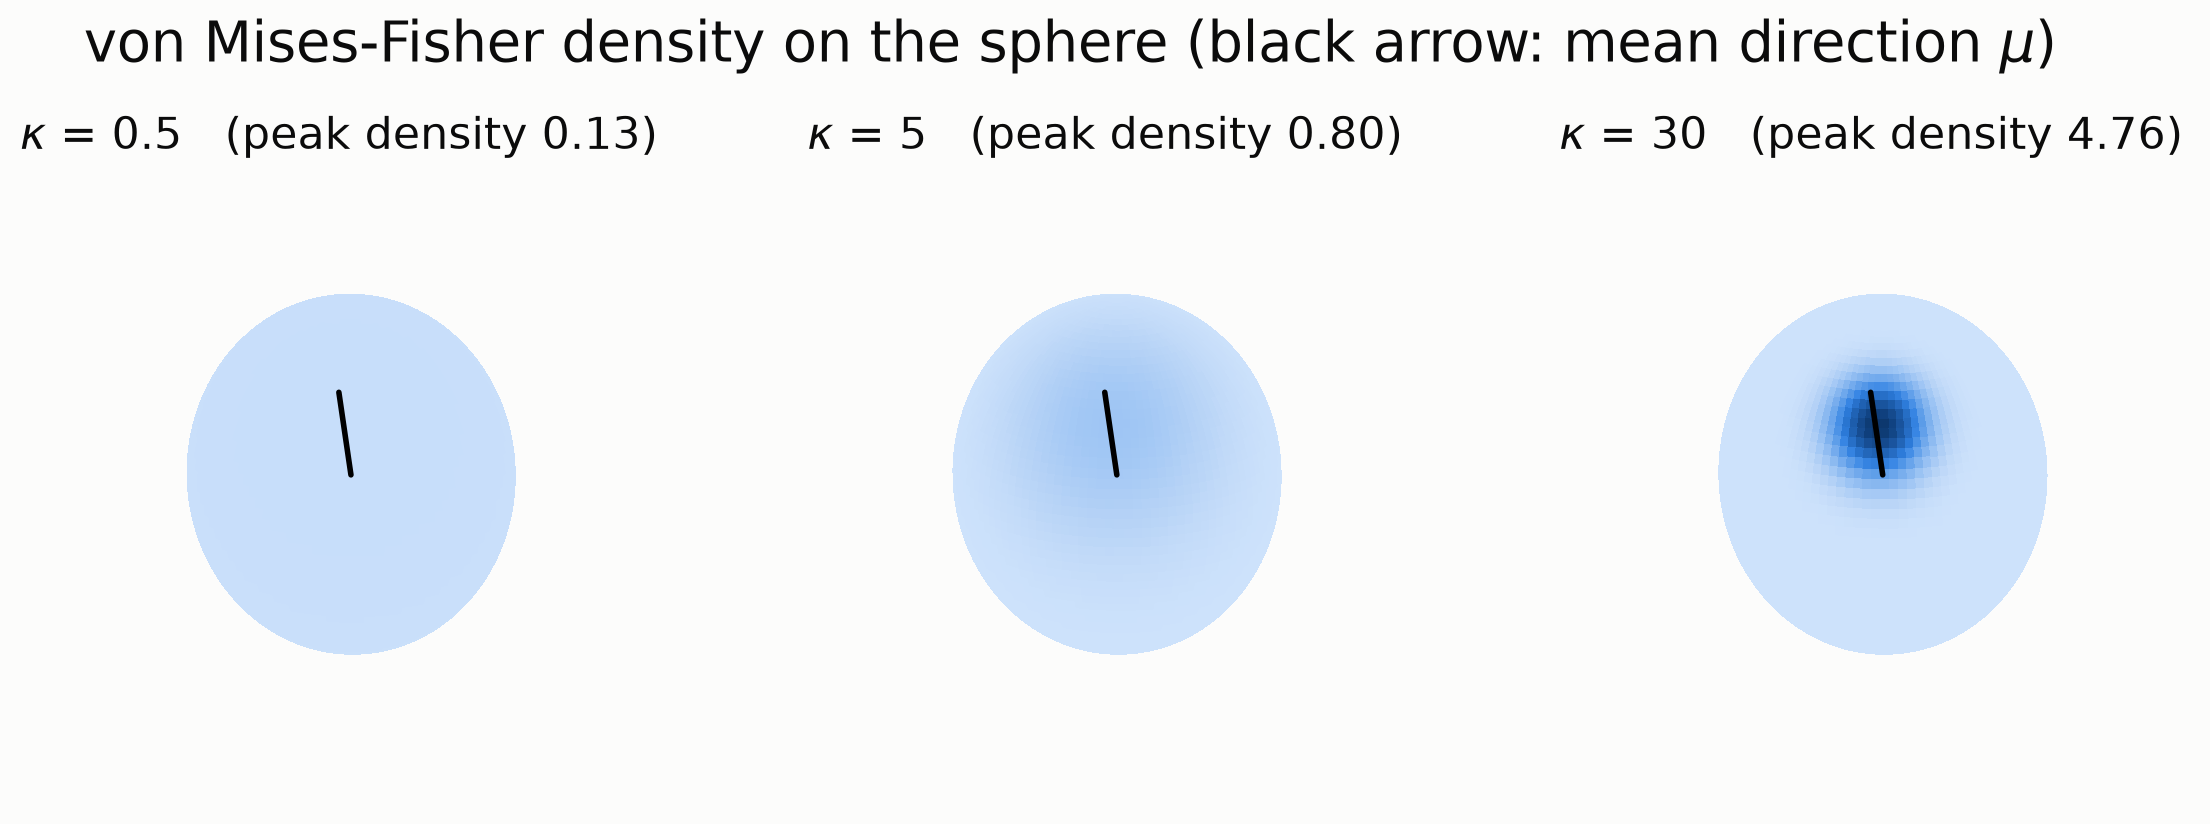

In [ ]:
from matplotlib import cm
from matplotlib.colors import Normalize
mu3 = np.array([1.0, 0.6, 0.8])
mu3 /= np.linalg.norm(mu3)
u, v = np.mgrid[0:2 * np.pi:120j, 0:np.pi:60j]
sx, sy, sz = (np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v))
cosine = mu3[0] * sx + mu3[1] * sy + mu3[2] * sz

def vmf3_density(kappa):
    return kappa * np.exp(kappa * (cosine - 1.0)) / (2 * np.pi * (1.0 - np.exp(-2.0 * kappa))) if kappa > 0 else np.full_like(cosine, 1 / (4 * np.pi))
kappas_sphere = [0.5, 5.0, 30.0]
densities = [vmf3_density(k) for k in kappas_sphere]
norm = Normalize(vmin=0, vmax=max((dn.max() for dn in densities)))
_fig = plt.figure(figsize=(14, 4.8))
for idx, (_kappa, dens) in enumerate(zip(kappas_sphere, densities)):
    _ax = _fig.add_subplot(1, 3, idx + 1, projection='3d')
    _ax.plot_surface(sx, sy, sz, facecolors=SEQUENTIAL_CMAP(norm(dens)), rstride=1, cstride=1, linewidth=0, antialiased=False, shade=False)
    _ax.plot([0, 1.5 * mu3[0]], [0, 1.5 * mu3[1]], [0, 1.5 * mu3[2]], color='black', lw=2)
    _ax.set_box_aspect((1, 1, 1))
    _ax.set_axis_off()
    _ax.view_init(elev=20, azim=35)
    _ax.set_title(f'$\\kappa$ = {_kappa:g}   (peak density {dens.max():.2f})')
_fig.suptitle('von Mises-Fisher density on the sphere (black arrow: mean direction $\\mu$)')
plt.gcf()

### The angle to the mean, and why dimension matters

Because $f$ depends on $x$ only through $\theta=\arccos(\mu^{\top}x)$, the natural summary of a vMF
sample in *any* dimension is the distribution of that angle:

$$
f(\theta)\;\propto\;e^{\kappa\cos\theta}\,\sin^{d-2}\theta,\qquad\theta\in[0,\pi].
$$

The factor $\sin^{d-2}\theta$ is the surface area of the "ring" at angle $\theta$, and it is what makes high
dimensions counter-intuitive: the density itself always peaks at $\theta=0$, but the *angle* of a
typical draw does not. The mode of $f(\theta)$ solves $\kappa\sin^2\theta=(d-2)\cos\theta$, i.e.
$\theta^\star\approx\sqrt{(d-2)/\kappa}$ when $\kappa\gg d$ but much larger when $\kappa$ is comparable to $d$
(for $d=768$, $\kappa=300$ it is about $70^\circ$). One therefore needs $\kappa$ growing with $d$ to keep clusters tight. `vmf_angle_density` computes this density, and
`vmf_cap_angle(kappa, d, mass)` gives the angular radius of the spherical cap that holds a given
probability mass -- the vMF analogue of a confidence ellipse, used by `plot_vmf` below.

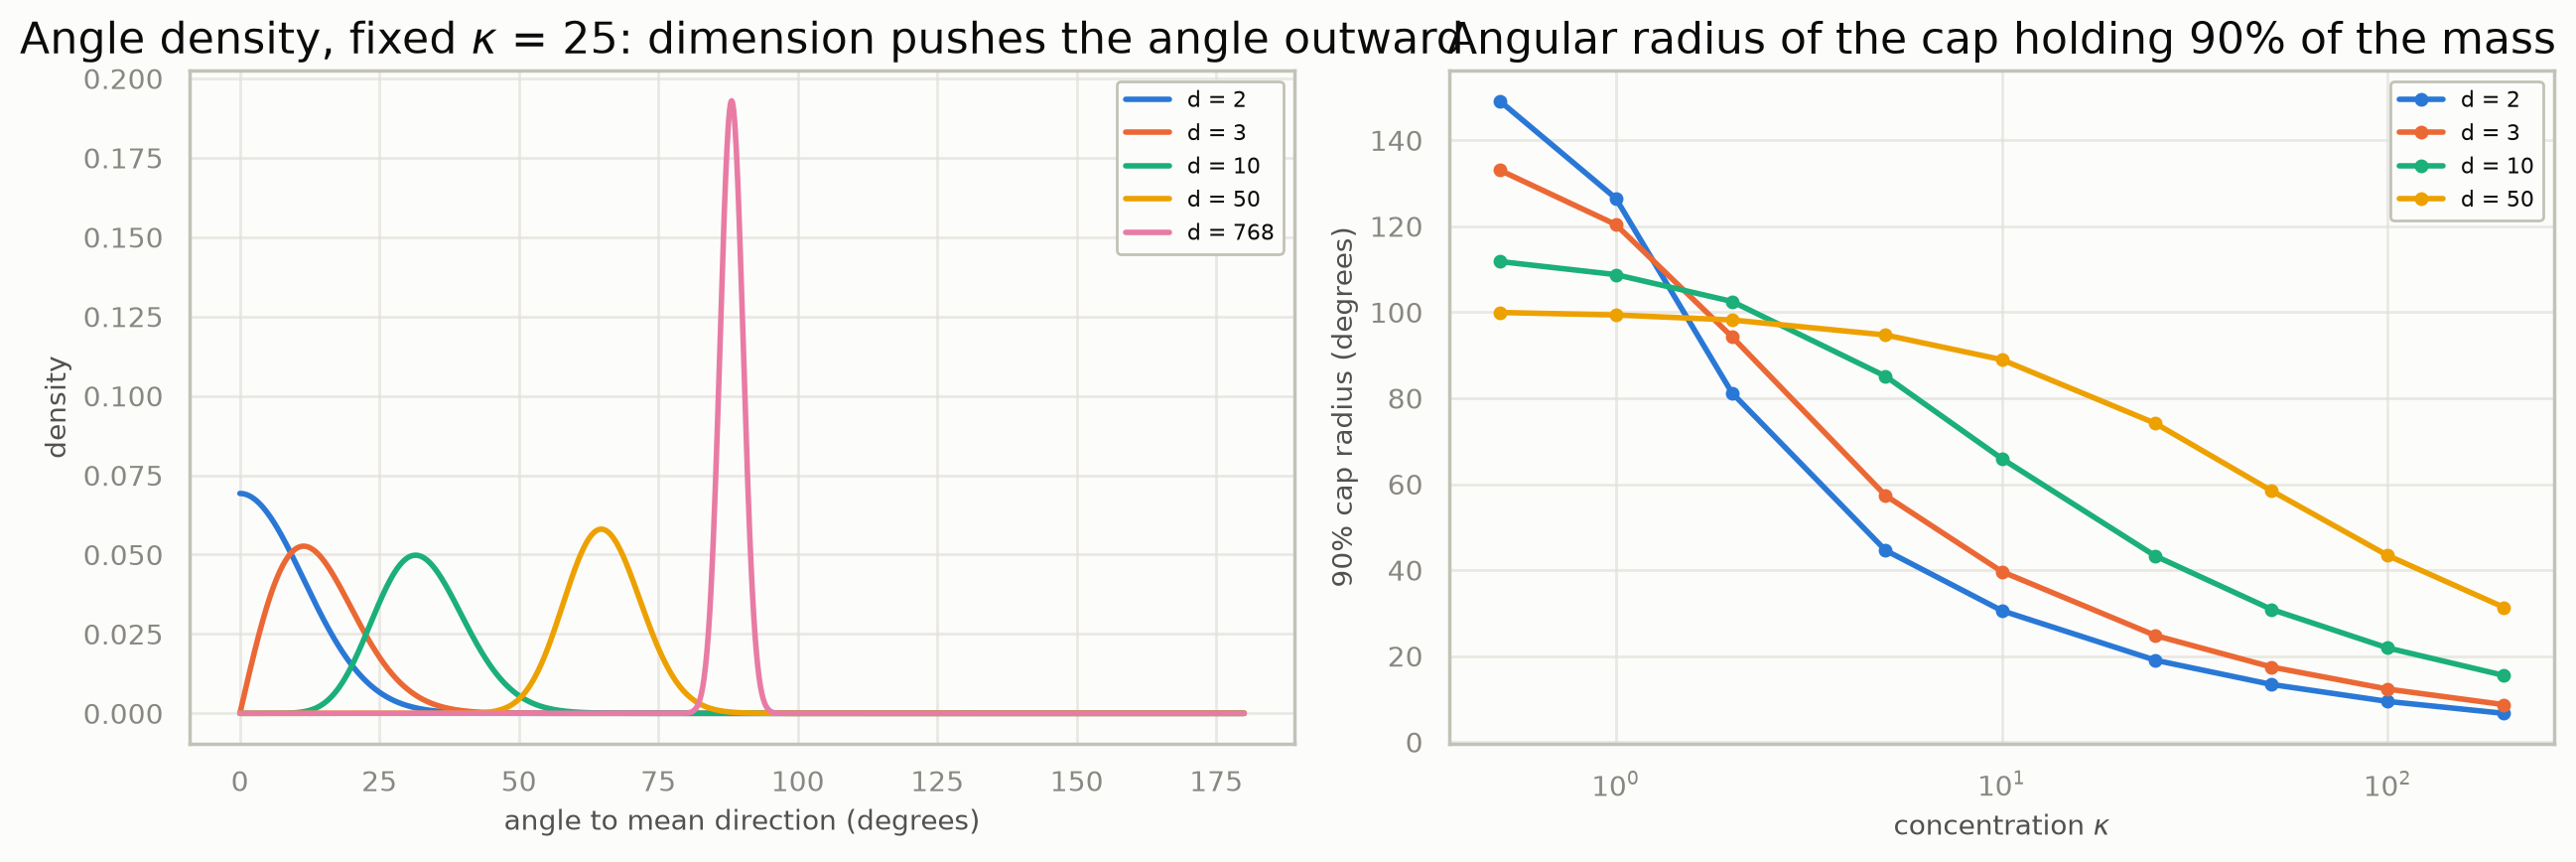

In [ ]:
theta = np.linspace(0, np.pi, 1500)
_fig, _axes = plt.subplots(1, 2, figsize=(13, 4.5))
for _d_demo, _color in zip([2, 3, 10, 50, 768], CATEGORICAL_PALETTE):
    _axes[0].plot(np.degrees(theta), vmf_angle_density(25.0, _d_demo, theta) * np.pi / 180, color=_color, label=f'd = {_d_demo}')
_axes[0].set_xlabel('angle to mean direction (degrees)')
_axes[0].set_ylabel('density')
_axes[0].set_title('Angle density, fixed $\\kappa$ = 25: dimension pushes the angle outward')
_axes[0].legend()
for _d_demo, _color in zip([2, 3, 10, 50], CATEGORICAL_PALETTE):
    kap = np.array([0.5, 1, 2, 5, 10, 25, 50, 100, 200])
    cap90 = [np.degrees(vmf_cap_angle(k, _d_demo, 0.9)) for k in kap]
    _axes[1].plot(kap, cap90, marker='o', ms=4, color=_color, label=f'd = {_d_demo}')
_axes[1].set_xscale('log')
_axes[1].set_xlabel('concentration $\\kappa$')
_axes[1].set_ylabel('90% cap radius (degrees)')
_axes[1].set_title('Angular radius of the cap holding 90% of the mass')
_axes[1].legend()
plt.tight_layout()
plt.gcf()

## How EM estimates a vMF mixture

The E-step is the generic one -- responsibilities $r_{ik}\propto\pi_kf(x_i\mid\mu_k,\kappa_k)$ -- with the vMF density
$\log f=\log C_d(\kappa_k)+\kappa_k\,\mu_k^{\top}x$. For the M-step form each component's **resultant vector**

$$
\mathbf{R}_k=\sum_i r_{ik}\,x_i,\qquad \bar R_k=\frac{\lVert\mathbf{R}_k\rVert}{n_k}\in[0,1],\qquad n_k=\sum_ir_{ik},
$$

the responsibility-weighted mean vector and its length (close to 1 when the points are nearly parallel). The
maximum-likelihood updates are

$$
\pi_k=\frac{n_k}{n},\qquad
\mu_k=\frac{\mathbf{R}_k}{\lVert\mathbf{R}_k\rVert},\qquad
A_d(\hat\kappa_k)=\bar R_k,\quad A_d(\kappa)=\frac{I_{d/2}(\kappa)}{I_{d/2-1}(\kappa)}.
$$

The mean direction is the normalised average direction; the concentration is the value at which the *expected* resultant
length $A_d(\kappa)$ of a vMF equals the observed $\bar R_k$. $A_d(\kappa)=\bar R$ has no closed-form solution, so `tgmm`
follows Banerjee et al.: start from the approximation $\kappa^{(0)}=\bar R(d-\bar R^2)/(1-\bar R^2)$ and refine with two
Newton steps using $A_d'(\kappa)=1-A_d^2-\tfrac{d-1}{\kappa}A_d$. The plot shows $A_d(\kappa)$ and the approximation
error for a few dimensions.

With `concentration='shared'`, one $\kappa$ is solved from the pooled resultant length $\sum_k\lVert\mathbf{R}_k\rVert/\sum_kn_k$.

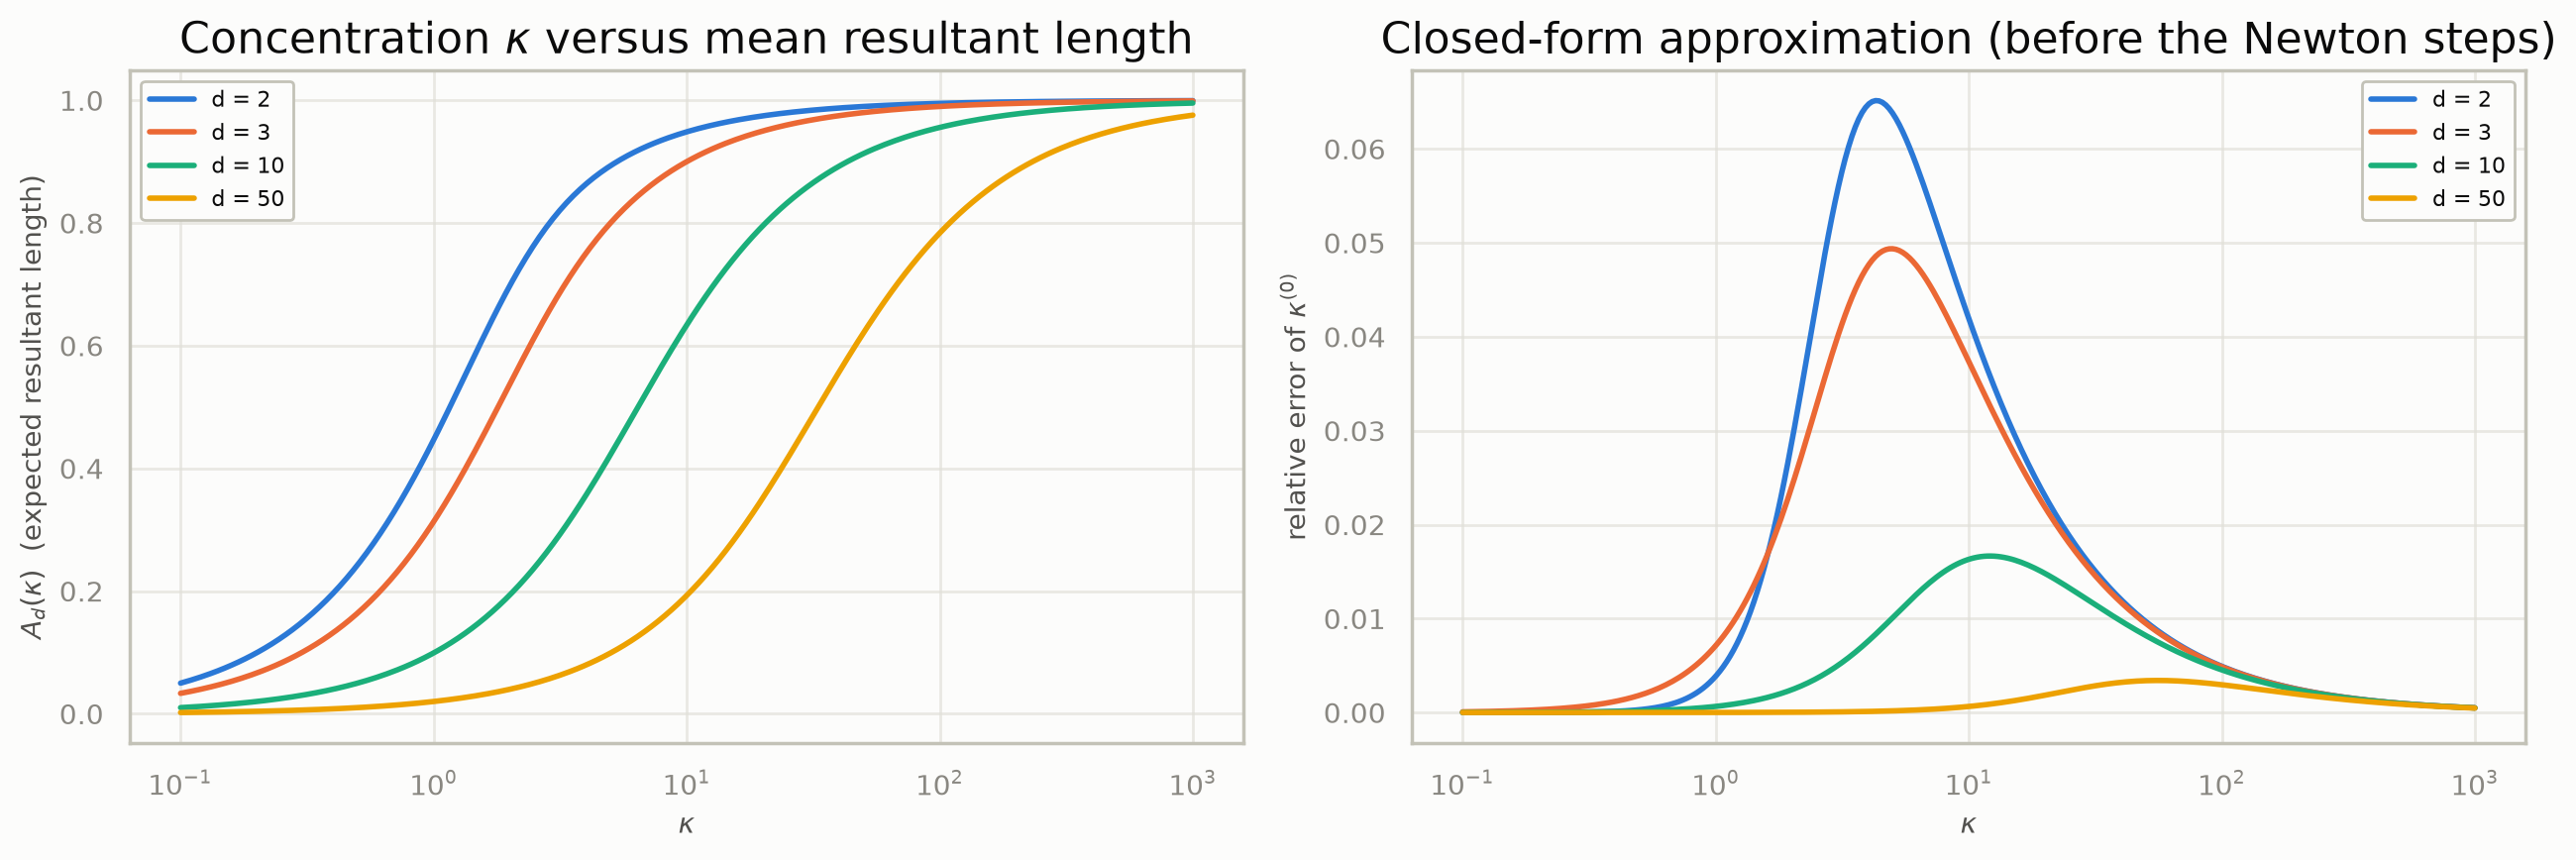

In [ ]:
def A_d(kappa, d):
    """Mean resultant length of a vMF: I_{d/2}(kappa) / I_{d/2-1}(kappa), via scaled Bessel functions."""
    return ive(d / 2, kappa) / ive(d / 2 - 1, kappa)

def banerjee_kappa(r_bar, d):
    return r_bar * (d - r_bar ** 2) / (1 - r_bar ** 2)
kappa_grid = np.logspace(-1, 3, 300)
_fig, _axes = plt.subplots(1, 2, figsize=(13, 4.5))
for _d_demo, _color in zip([2, 3, 10, 50], CATEGORICAL_PALETTE):
    r_bar = A_d(kappa_grid, _d_demo)
    _axes[0].semilogx(kappa_grid, r_bar, color=_color, label=f'd = {_d_demo}')
    _axes[1].semilogx(kappa_grid, banerjee_kappa(r_bar, _d_demo) / kappa_grid - 1, color=_color, label=f'd = {_d_demo}')
_axes[0].set_xlabel('$\\kappa$')
_axes[0].set_ylabel('$A_d(\\kappa)$  (expected resultant length)')
_axes[0].set_title('Concentration $\\kappa$ versus mean resultant length')
_axes[1].set_xlabel('$\\kappa$')
_axes[1].set_ylabel('relative error of $\\kappa^{(0)}$')
_axes[1].set_title('Closed-form approximation (before the Newton steps)')
for _ax in _axes:
    _ax.legend()
plt.tight_layout()
plt.gcf()

### Checking the M-step against the library

The following cell fits a mixture on synthetic directions in $d=5$, recomputes $n_k$, $\mathbf{R}_k$, $\bar R_k$ from the model's own
responsibilities, solves $A_d(\kappa)=\bar R_k$ **exactly** with a root-finder, and compares with the fitted `means_` and `kappa_`.
(The agreement is up to the convergence tolerance, since the stored parameters come from the previous iteration's responsibilities.)

In [ ]:
def sample_vmf_mixture(mean_directions, kappas, n_per, seed):
    '''Draw from a known vMF mixture using tgmm's own (Wood, 1994) sampler.'''
    mus = torch.tensor(mean_directions, dtype=torch.float32)
    mus = mus / mus.norm(dim=1, keepdim=True)
    K, d_ = mus.shape
    truth = VonMisesFisherMixture(n_components=K, n_features=d_)
    truth.weights_ = torch.full((K,), 1.0 / K)
    truth.means_ = mus
    truth.kappa_ = torch.tensor(kappas, dtype=torch.float32)
    torch.manual_seed(seed)
    X_ = torch.cat([truth._sample_component(k, n_per) for k in range(K)])
    y_ = torch.arange(K).repeat_interleave(n_per)
    return X_, y_


torch.manual_seed(0)
dirs5 = torch.randn(3, 5)
X5, y5 = sample_vmf_mixture(dirs5.tolist(), [30.0, 60.0, 15.0], 400, seed=5)
vmf5 = VonMisesFisherMixture(n_components=3, random_state=SEED, tol=1e-10, max_iter=5 * MAX_ITER).fit(X5.double())

X5d = X5.double()
resp = vmf5.predict_proba(X5d).detach().double()
nk = resp.sum(0)
R = resp.T @ X5d                                   # (K, d) resultant vectors
R_bar = R.norm(dim=1) / nk
mu_hat = R / R.norm(dim=1, keepdim=True)
kappa_exact = [brentq(lambda k: A_d(k, 5) - rb, 1e-3, 1e5) for rb in R_bar.tolist()]

print('mean direction: max |mu_k - R_k/||R_k||| =', (vmf5.means_.double() - mu_hat).abs().max().item())
print('kappa  (library):      ', vmf5.kappa_.numpy().round(3))
print('kappa  (root of A_d):  ', np.round(kappa_exact, 3))
print('kappa  (Banerjee only):', banerjee_kappa(R_bar.numpy(), 5).round(3))
print('true kappa:            ', [30.0, 60.0, 15.0], '(components may be permuted)')

mean direction: max |mu_k - R_k/||R_k||| = 5.1055253691423275e-08
kappa  (library):       [28.574 14.838 62.92 ]
kappa  (root of A_d):   [28.574 14.838 62.92 ]
kappa  (Banerjee only): [28.997 15.195 63.385]
true kappa:             [30.0, 60.0, 15.0] (components may be permuted)


## Fitting and plotting a vMF mixture on the circle and the sphere

`plot_gmm` draws Euclidean ellipses and cannot show data that lives on a sphere. `plot_vmf` is its vMF
counterpart for $d=2$ (circle) and $d=3$ (sphere): points coloured by predicted component, each
**mean direction** $\mu_k$ as an arrow, and each concentration $\kappa_k$ as nested **spherical caps**
(arcs on the circle, rings on the sphere) enclosing 50% and 90% of the component's probability mass.
Below, three vMF clusters with different concentrations are sampled, fitted, and drawn.

In [ ]:
X_circle, y_circle = sample_vmf_mixture([[1, 0], [0, 1], [-1, -0.3]], [40.0, 15.0, 80.0], 200, seed=1)
X_sphere, y_sphere = sample_vmf_mixture([[1, 0, 0], [0, 1, 0.3], [-0.5, -0.5, 1]], [40.0, 15.0, 80.0], 200, seed=2)
vmf_circle = VonMisesFisherMixture(n_components=3, random_state=SEED, n_init=min(3, N_INIT)).fit(X_circle)
vmf_sphere = VonMisesFisherMixture(n_components=3, random_state=SEED, n_init=min(3, N_INIT)).fit(X_sphere)

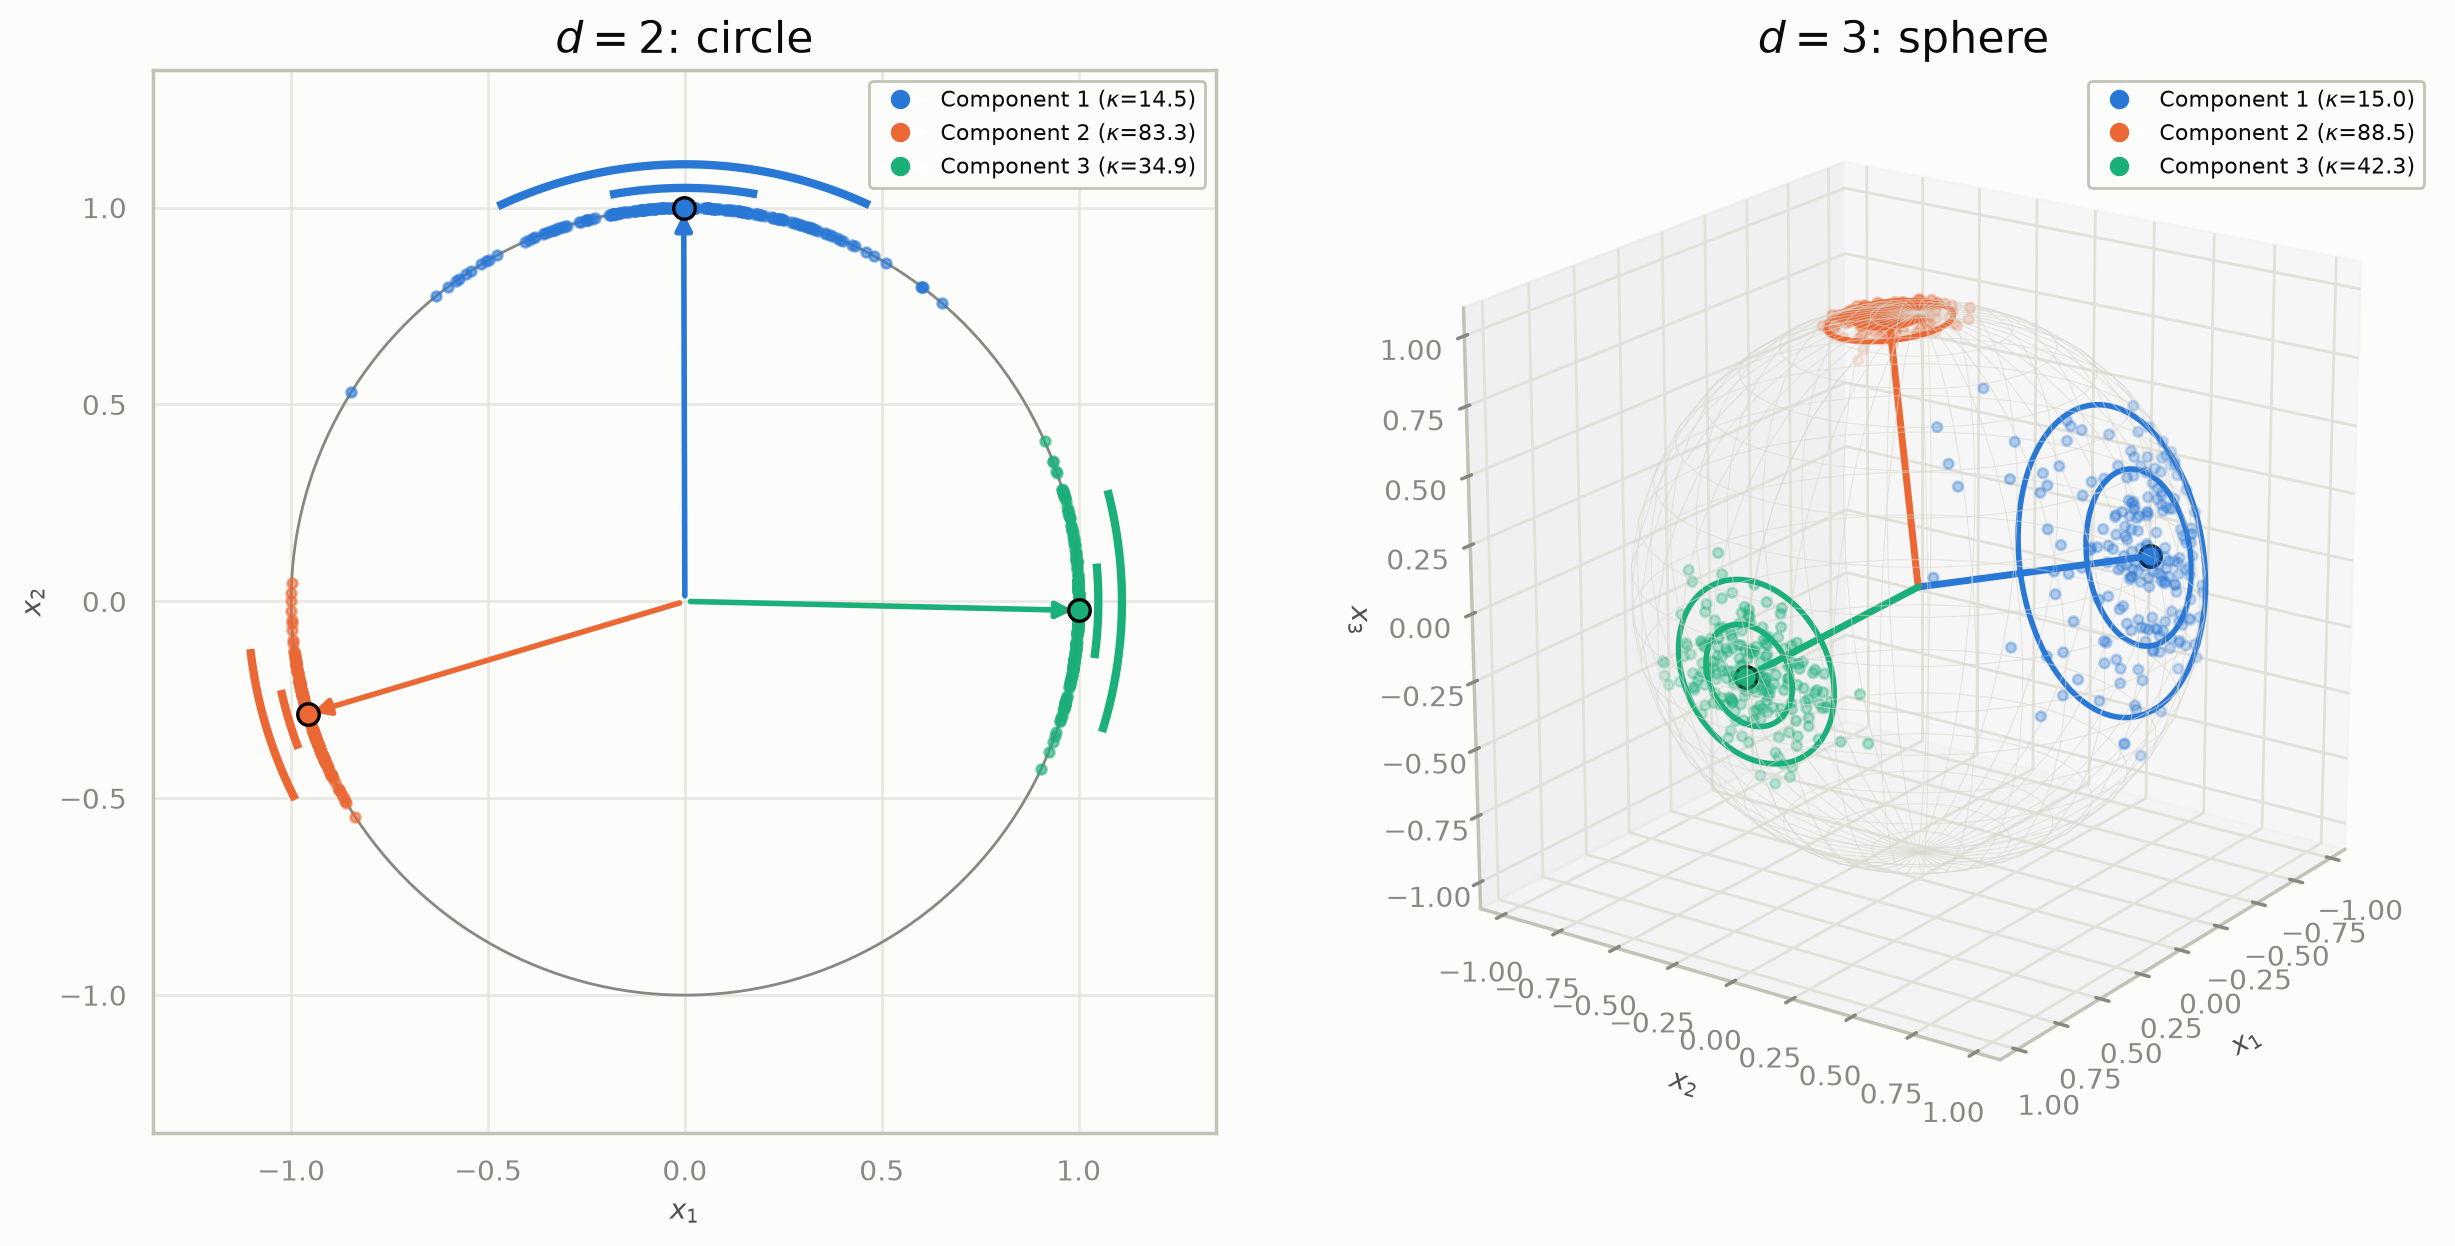

In [ ]:
_fig = plt.figure(figsize=(13, 6.2))
_ax1 = _fig.add_subplot(1, 2, 1)
plot_vmf(X_circle, vmf_circle, ax=_ax1, title='$d=2$: circle')
_ax2 = _fig.add_subplot(1, 2, 2, projection='3d')
plot_vmf(X_sphere, vmf_sphere, ax=_ax2, title='$d=3$: sphere')
plt.tight_layout()
plt.gcf()

In [ ]:
print('true kappa:  [40, 15, 80]')
print('fitted kappa (circle):', vmf_circle.kappa_.numpy().round(1))
print('fitted kappa (sphere):', vmf_sphere.kappa_.numpy().round(1))

true kappa:  [40, 15, 80]
fitted kappa (circle): [14.5 83.3 34.9]
fitted kappa (sphere): [15.  88.5 42.3]


The arrows are the fitted mean directions, the caps shrink as $\kappa$ grows (compare the wide,
low-concentration component with the tight one), and the points should fill roughly 50% / 90% of their
component's inner / outer cap. Passing `true_labels=` colours points by ground truth instead, to spot
where the model's partition disagrees with it.

For a quantitative version of the same check -- valid in **any** dimension -- `plot_vmf_cosine`
histograms, per component, the angle between each assigned point and the component's mean direction
and overlays the fitted $f_{\kappa_k}(\theta)$ (dashed). If the vMF assumption holds, histogram and curve agree.

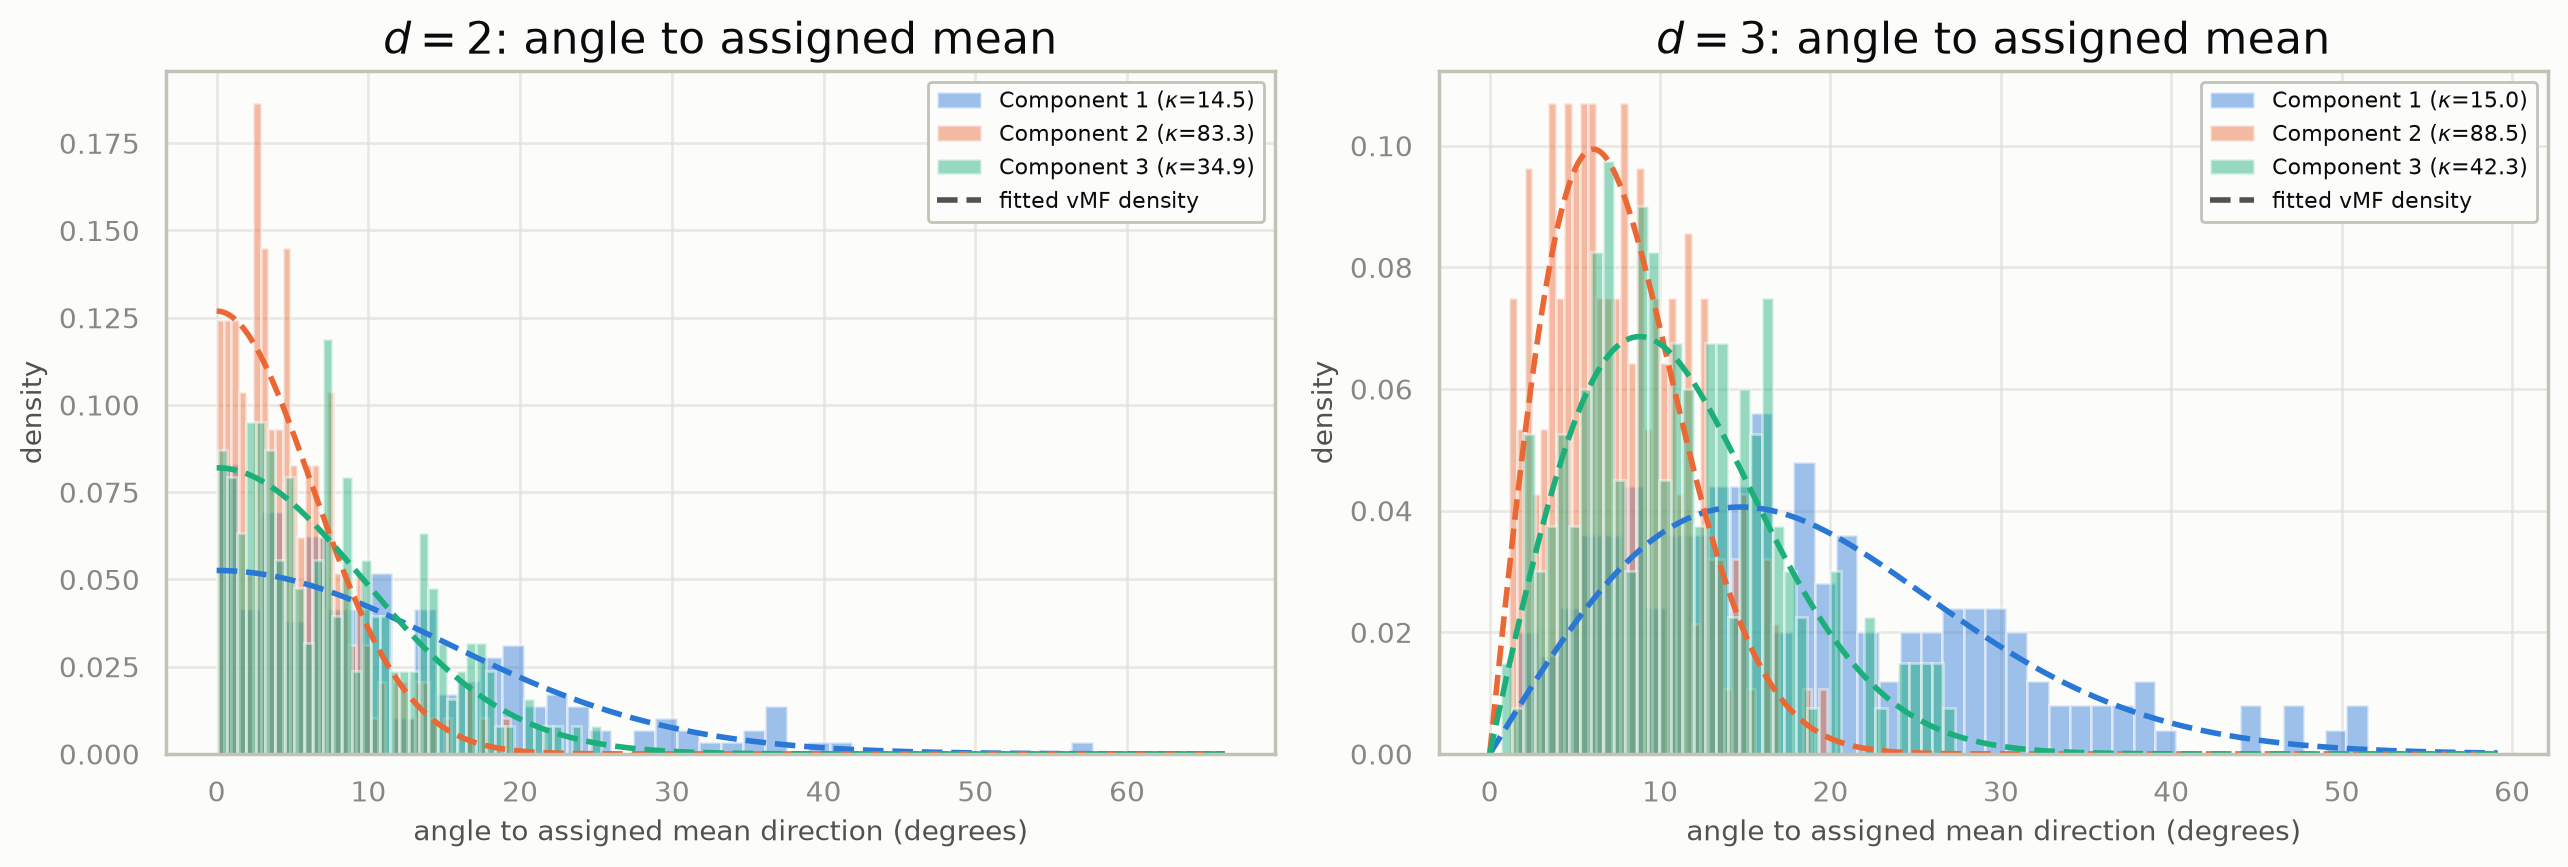

In [ ]:
_fig, _axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_vmf_cosine(X_circle, vmf_circle, ax=_axes[0], title='$d=2$: angle to assigned mean')
plot_vmf_cosine(X_sphere, vmf_sphere, ax=_axes[1], title='$d=3$: angle to assigned mean')
plt.tight_layout()
plt.gcf()

### Shared versus per-component concentration

By default every component gets its own $\kappa_k$ (`concentration='per_component'`). `'shared'` solves one $\kappa$ from the pooled resultant length: it saves $K-1$ parameters, which pays off when clusters have similar spread. On the sphere data above, where the clusters have
deliberately different spreads, the per-component model should win; compare their information criteria (both are vMF models, so these
are comparable):

In [ ]:
for _conc in ['per_component', 'shared']:
    _m = VonMisesFisherMixture(n_components=3, concentration=_conc, random_state=SEED, n_init=min(3, N_INIT)).fit(X_sphere)
    _ari = ClusteringMetrics.adjusted_rand_score(y_sphere, _m.predict(X_sphere))
    print(f'{_conc:<14} kappa_={_m.kappa_.numpy().round(1)}  BIC={_m.bic(X_sphere):9.1f}  ICL={_m.icl(X_sphere):9.1f}  ARI={_ari:.3f}')

per_component  kappa_=[15.  88.5 42.3]  BIC=    421.4  ICL=    421.4  ARI=1.000
shared         kappa_=[29.5 29.5 29.5]  BIC=    717.2  ICL=    717.5  ARI=0.995


## High-dimensional unit-norm embeddings

Simulating the kind of data a real text-embedding pipeline produces: 768-dimensional vectors,
L2-normalized before clustering by cosine similarity. We compare `VonMisesFisherMixture`
against `GaussianMixture(covariance_type='diag')` fit on the same normalized data -- a
reasonable baseline, just one that doesn't know the data lives on a sphere -- using `icl`
(within each family) and cosine silhouette (comparable across both).

In [ ]:
d = 768
n_per = 150
K_true = 4

gen = torch.Generator().manual_seed(SEED)
true_mus = torch.randn(K_true, d, generator=gen)
true_mus = true_mus / true_mus.norm(dim=1, keepdim=True)
true_kappa = 300.0

# Generate actual vMF-distributed data by constructing a VonMisesFisherMixture
# with known parameters and using its own (Wood, 1994) rejection sampler --
# more faithful than an ad-hoc approximation, and exercises the same code path
# being demonstrated below.
true_model = VonMisesFisherMixture(n_components=K_true, n_features=d)
true_model.weights_ = torch.full((K_true,), 1.0 / K_true)
true_model.means_ = true_mus
true_model.kappa_ = torch.full((K_true,), true_kappa)

torch.manual_seed(SEED)
X_list, labels_list = [], []
for _k in range(K_true):
    X_list.append(true_model._sample_component(_k, n_per))
    labels_list.append(torch.full((n_per,), _k))
X_emb = torch.cat(X_list)
labels_true = torch.cat(labels_list)

print(f'X_emb shape: {tuple(X_emb.shape)}, row norms (should be ~1): '
      f'{X_emb.norm(dim=1).min():.4f} - {X_emb.norm(dim=1).max():.4f}')

X_emb shape: (600, 768), row norms (should be ~1): 1.0000 - 1.0000


In [ ]:
vmf = VonMisesFisherMixture(n_components=K_true, concentration='per_component',
                             random_state=SEED, n_init=min(3, N_INIT), max_iter=100)
vmf.fit(X_emb)

gmm_diag = GaussianMixture(n_components=K_true, covariance_type='diag',
                            random_state=SEED, n_init=min(3, N_INIT))
gmm_diag.fit(X_emb)

pred_vmf = vmf.predict(X_emb)
pred_gmm = gmm_diag.predict(X_emb)

ari_vmf = ClusteringMetrics.adjusted_rand_score(labels_true, pred_vmf)
ari_gmm = ClusteringMetrics.adjusted_rand_score(labels_true, pred_gmm)
sil_vmf = ClusteringMetrics.silhouette_score(X_emb, pred_vmf, metric='cosine')
sil_gmm = ClusteringMetrics.silhouette_score(X_emb, pred_gmm, metric='cosine')

print(f'VonMisesFisherMixture:  ARI={ari_vmf:.3f}  cosine silhouette={sil_vmf:.3f}  '
      f'ICL={vmf.icl(X_emb):.1f}  fitted kappa={vmf.kappa_.mean().item():.1f} (true={true_kappa})')
print(f'GaussianMixture(diag):  ARI={ari_gmm:.3f}  cosine silhouette={sil_gmm:.3f}  '
      f'ICL={gmm_diag.icl(X_emb):.1f}')

VonMisesFisherMixture:  ARI=1.000  cosine silhouette=0.111  ICL=-1791013.0  fitted kappa=311.3 (true=300.0)
GaussianMixture(diag):  ARI=1.000  cosine silhouette=0.111  ICL=-1777652.4


### Visual checks in 768 dimensions

We cannot draw 768 dimensions, but the vMF model suggests the right summaries. First, the angle
histogram of each cluster against its fitted density -- the same plot as for the circle and the sphere, now with the
$\sin^{d-2}\theta$ effect fully in force: with $\kappa\approx300$ in $d=768$ the typical angle to the
mean is far from 0, yet the fitted density matches it. Second, the **cosine-similarity matrix** of the
points sorted by predicted cluster: a clean block-diagonal structure means within-cluster directions
agree and between-cluster directions do not.

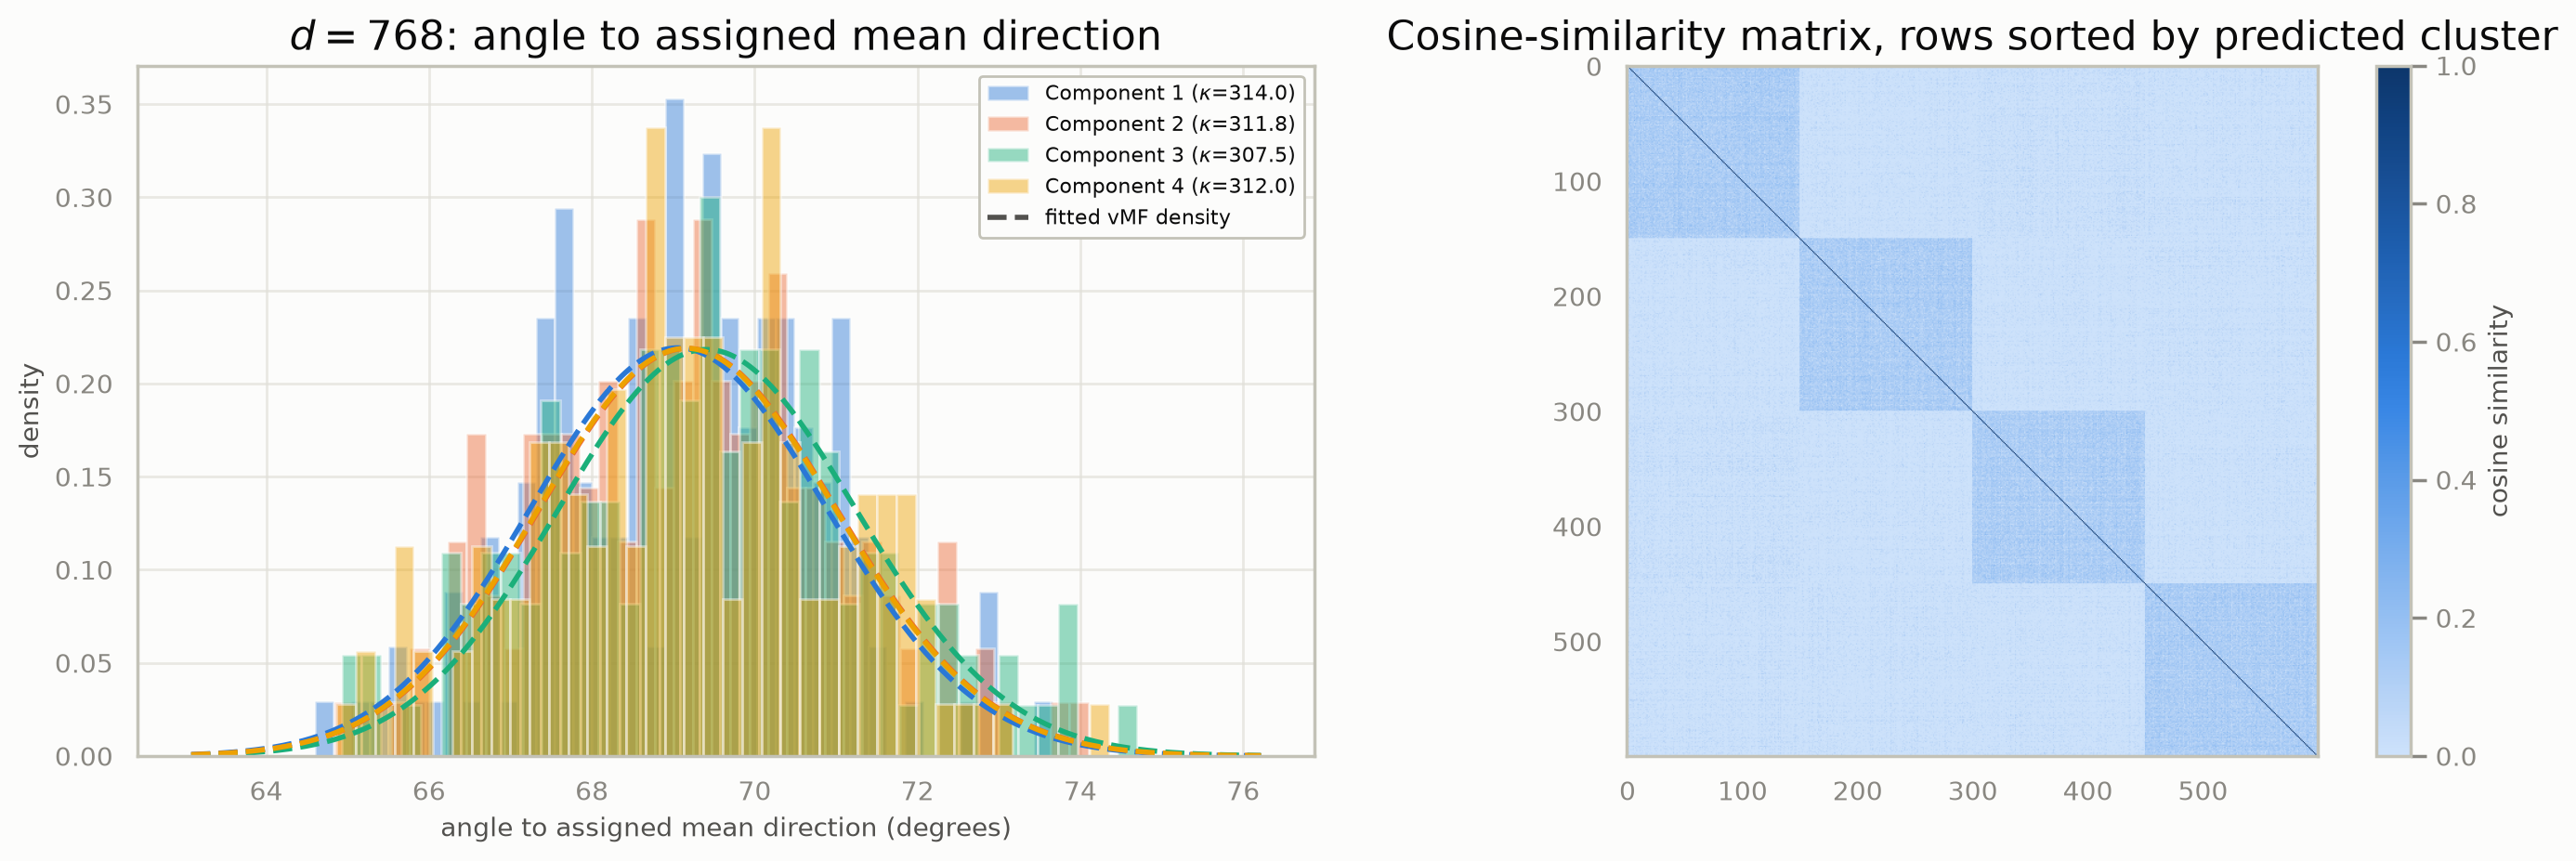

In [ ]:
_fig, _axes = plt.subplots(1, 2, figsize=(14, 4.8))
plot_vmf_cosine(X_emb, vmf, ax=_axes[0], title='$d=768$: angle to assigned mean direction')
order = torch.argsort(pred_vmf)
sim = (X_emb[order] @ X_emb[order].T).numpy()
im = _axes[1].imshow(sim, cmap=SEQUENTIAL_CMAP, vmin=0, vmax=sim.max())
_axes[1].set_title('Cosine-similarity matrix, rows sorted by predicted cluster')
_axes[1].grid(False)
_fig.colorbar(im, ax=_axes[1], label='cosine similarity')
plt.tight_layout()
plt.gcf()

### Which comparisons are meaningful?

Both models recover the 4 clusters perfectly here, so their partitions -- and hence ARI and cosine silhouette -- coincide; what differs is what the
fit *says* about the data. `VonMisesFisherMixture` recovers the concentration `kappa_`, close to the value used to generate the data (the
fit above is within a few percent), a direct reflection of the generative process.

Its `icl`/`bic`/`aic` are meaningful only compared to **other vMF fits** (different $K$, shared versus per-component $\kappa$). They must not be compared with a `GaussianMixture`'s:
a vMF density lives on the sphere (a set of zero volume in $\mathbb{R}^d$), the Gaussian density on all of $\mathbb{R}^d$, so
their log-likelihoods are densities with respect to different measures. Compare *across* families with a measure that does not depend on the density, such as a
cosine-based clustering metric or the agreement with known labels. This differs from Gaussian versus
[Student-t](16_student_t.ipynb), which share a base measure and can be compared directly.

On real embeddings, where classes overlap more, the vMF model's advantage is that it does not spend parameters modelling variation in vector
*length*, which L2-normalisation has already thrown away.

## Summary

- A vMF density depends on $x$ only through $\mu^{\top}x$; $\kappa$ sets the width, $\kappa=0$ is the uniform distribution on the sphere, and in
  high dimension the typical angle to the mean is large even for big $\kappa$ (the $\sin^{d-2}\theta$ factor).
- EM updates each mean direction as the normalised resultant vector and each $\kappa$ by solving $A_d(\kappa)=\bar R_k$ (Banerjee
  approximation plus Newton steps), matching an exact root-finder to the convergence tolerance.
- `plot_vmf` draws vMF mixtures on the circle and the sphere (mean directions plus probability-mass caps), and `plot_vmf_cosine` checks the fit in any
  dimension by comparing angle histograms with the fitted density.
- Information criteria are comparable only *within* the vMF family; use cosine-based metrics or labels to compare with a Gaussian baseline.
- The model shares `GaussianMixture`'s EM toolkit (`algorithm`, `temperature`, `step_size`, `n_init`) and its semi-supervised `fit(X, labels=...)`.

**Next:** [18 -- Semi-Supervised and Positive-Unlabeled Fitting](18_semi_supervised_pu.ipynb), or back to
[16 -- Student-t Mixtures](16_student_t.ipynb).